In [4]:
import matplotlib.colors as mcolors
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

# Your specific colors
color_list = ['#0283F8', '#FFA500','#00C49A', '#FF0059']
# Create a ListedColormap
custom_cmap = mcolors.LinearSegmentedColormap.from_list("CustomColormap", color_list)

colors = {
    "red":'#FF0059',
    "blue":'#0283F8',
    "green":'#00C49A',
    "orange":'#FFA500'
}


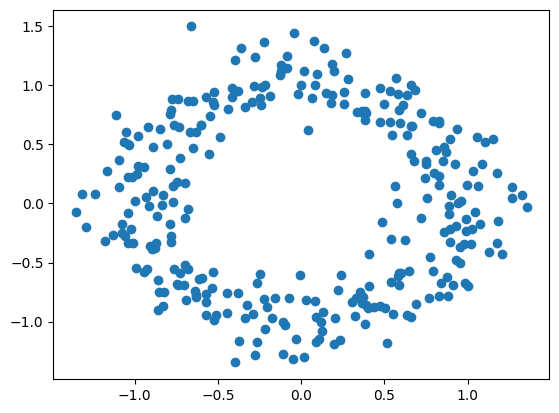

In [5]:
from sklearn.metrics import pairwise_distances

bounds = 8*np.pi
size = 300
noise = 0.2
theta = np.linspace(0, bounds, size)
x = np.cos(theta)*np.random.normal(loc=1, scale=noise, size=size)
y = np.sin(theta)*np.random.normal(loc=1, scale=noise, size=size)
adj_matrix = pairwise_distances(np.c_[x,y])
plt.scatter(x,y)

Rips(maxdim=1, thresh=inf, coeff=2, do_cocycles=False, n_perm = None, verbose=True)


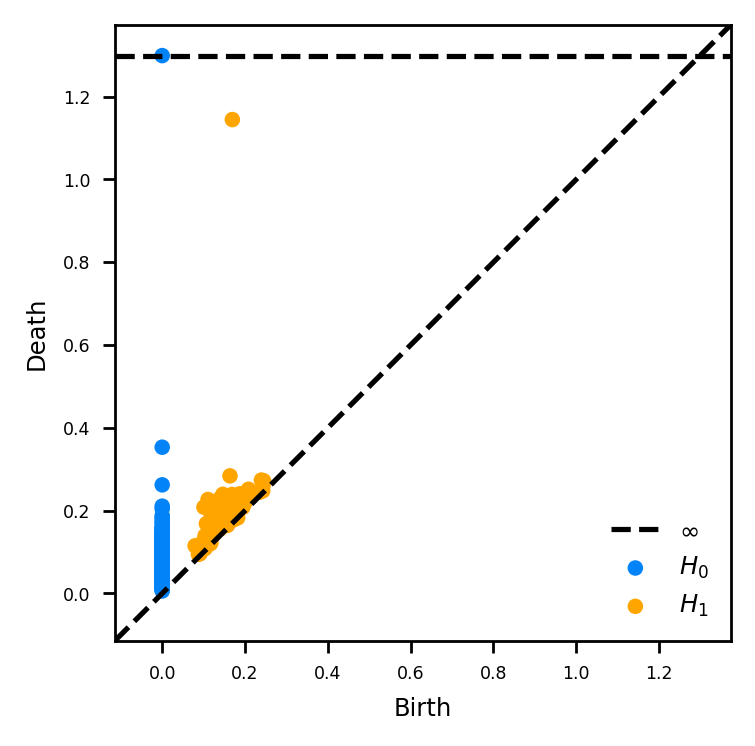

In [6]:
import utils
from ripser import Rips
# Create figure with 3D subplots
fig,ax = plt.subplots(figsize=(3.2, 3.2),dpi=250)
MAXDIM = 1
rips = Rips(maxdim=MAXDIM)
diags=rips.fit_transform(adj_matrix,distance_matrix=True)
utils.plot_diagrams(diags,color_list,legend=True,ax = ax)
ax.tick_params(axis='both', which='major', labelsize=5)
#plt.savefig("Figures/example_sine_embedding.png",bbox_inches='tight')
plt.show()

In [7]:
def time_adjacency_matrix():
    def inner_time_adjacency_matrix(simplex_j, simplex_i):
        if are_simplices_adjacent(simplex_j, simplex_i):
            return time_weight(simplex_i, simplex_j)
        else:
            return 0

    return inner_time_adjacency_matrix

def time_matrix(matrix):
    def inner_time_matrix(simplex_j, simplex_i):
        a = matrix[simplex_i[0]][simplex_i[1]]
        b = matrix[simplex_j[0]][simplex_j[1]]
        return np.abs(a - b)
    return inner_time_matrix

def time_label(simplex_i):
    return adj_matrix[simplex_i[0],simplex_i[0]]

def time_weight(simp1, simp2) -> float:
    return np.abs(time_label(simp1) - time_label(simp2))
    


def are_simplices_adjacent(simplex1, simplex2):
    # Count common elements between the two tuples
    common_elements = set(simplex1).intersection(set(simplex2))
    # Two simplices are adjacent if they share exactly n-1 elements
    if len(common_elements) == len(simplex1) - 1:
        return 1
    return 0


def time_basic_matrix(
    inv_row_map,
) -> np.ndarray:
    n = len(inv_row_map)
    weight_matrix = np.zeros((n, n))

    for i in range(n):
      simplex_i = inv_row_map[i]
      weight_matrix[i,i] = np.abs(simplex_i[0]-simplex_i[1])
    return weight_matrix


def edge_length_function(points):
    def edge_length(simp1, simp2):
        if simp1 == simp2:
            return np.linalg.norm(points[simp1[0]] - points[simp1[1]])
        else:
            return 0

    return edge_length


#W_global = absolute_time_difference(n_simplices)
#global_cycle = optimize_cycle(W_global, x_orig, boundary_matrix, n_simplices)

In [8]:
# get all cycles bigger than the given bound
import recycle as re
import gudhi
rips = Rips(maxdim=MAXDIM)
diags=rips.fit_transform(adj_matrix,distance_matrix=True)
persistence = diags[1][:, 1] - diags[1][:, 0]
longest_cycle = np.argsort(persistence)[-1]
birth, death = diags[1][longest_cycle]
# use death to calculate max_edge_length
max_edge_length = death * 1.01  # give a bit of slack

dimension = 2
points = adj_matrix
#min_persistence = lower_bound
min_persistence = (death-birth)*0.9


gudhi_complex = re.core.create_simplicial_complex(points, max_edge_length, dimension,distance_matrix=True)
#gudhi_complex = gudhi.AlphaComplex(points=np.c_[x,y]).create_simplex_tree(dimension)
(
    representative,
    boundary_map,
    reduced_boundary_base,
    (birth_simplex,death_simplex)
) = re.core.get_representative_and_complex(gudhi_complex, dimension)

# Get the ACTUAL values of birth and death
birth,death = gudhi_complex.filtration(birth_simplex),gudhi_complex.filtration(death_simplex)
#min_persistence = (death - birth)*0.95

order_function = lambda s: (gudhi_complex.filtration(s), s)
# ISOLATED
np1_simplices = sorted(
    {
        simplex
        for simplex in reduced_boundary_base
        if gudhi_complex.filtration(simplex) <= (death - min_persistence)*1.01 #slack for rounding errors
    },
    key=order_function,
)
n_simplices = sorted(
    {
        tuple(sorted(simplex))
        for simplex, radius in gudhi_complex.get_filtration()
        if len(simplex) == dimension and radius <= (death - min_persistence)*1.01 #slack for rounding errors
    },
    key=order_function,
)
nm1_simplices = sorted(
    {
        tuple(sorted(simplex))
        for simplex, radius in gudhi_complex.get_filtration()
        if len(simplex) == dimension - 1 and radius <= (death - min_persistence)*1.01 #slack for rounding errors
    },
    key=order_function,
)
        
x_orig = re.core.lift_representative(representative, nm1_simplices, n_simplices)
boundary_matrix = re.core.build_boundary_matrix(n_simplices, np1_simplices)

Rips(maxdim=1, thresh=inf, coeff=2, do_cocycles=False, n_perm = None, verbose=True)


In [9]:
x_alt, status, len_objective_value = re.core.find_minimal_homologous_cycle(boundary_matrix, x_orig, None, use_gurobi=True) 
len_cycle = set([n_simplices[index] for index in np.argwhere(~np.isclose(x_alt,0)).flatten()])

#W = re.core.create_weight_matrix(n_simplices, time_adjacency_matrix())
W = re.core.create_weight_matrix(n_simplices, time_matrix(adj_matrix))
#W = None

# Run optimization
x_min, status, mean_objective_value = re.core.find_minimal_homologous_cycle(
    boundary_matrix, x_orig, W, use_gurobi=True
)
mean_cycle = set(
    [n_simplices[index] for index in np.argwhere(~np.isclose(x_min, 0)).flatten()]
)  # be carefull here with values close to zero, add a tolerance parameter




Set parameter Username
Set parameter LogFile to value "gurobi.log"
Using license file /Users/antonio/gurobi.lic
Academic license - for non-commercial use only - expires 2025-10-30

Gurobi Optimizer version 11.0.3 build v11.0.3rc0 (mac64[arm] - Darwin 24.3.0 24D70)
Copyright (c) 2024, Gurobi Optimization, LLC

Read LP format model from file /var/folders/n0/wk41mth910n6jkj_vdp1m4z00000gn/T/9df64eee96c040d985d2d0afd73f608e-pulp.lp
Reading time = 0.01 seconds
OBJ: 2277 rows, 6529 columns, 10479 nonzeros

CPU model: Apple M1 Pro
Thread count: 8 physical cores, 8 logical processors, using up to 8 threads

Optimize a model with 2277 rows, 6529 columns and 10479 nonzeros
Model fingerprint: 0xb99c7ff6
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [1e+00, 1e+00]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+00]
Presolve removed 1760 rows and 1769 columns
Presolve time: 0.01s
Presolved: 517 rows, 4760 columns, 11080 nonzeros

Iteration    Objective

In [10]:
def visualize_network(x, y, adj_matrix, extra_edges=None, color='red', ax=None, max_weight=None):
    # Create a new figure if ax is not provided
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 8))
    
    # Create a network from the adjacency matrix
    G = nx.from_numpy_array(np.array(adj_matrix))
    
    # Get positions for nodes using provided coordinates
    pos = {i: (xx, yy) for i, (xx, yy) in enumerate(zip(x, y))}
    
    # Draw edges with grayscale based on weight (before nodes so they appear behind)
    edges = G.edges(data=True)
    
    if max_weight is not None:
        # Filter edges based on max_weight
        edges = [(u, v, d) for u, v, d in edges if d['weight'] < max_weight]
    
    # Find the maximum weight for normalization
    max_val = max([d['weight'] for _, _, d in edges]) if edges else 1
    
    # Draw regular edges with full opacity and grayscale based on weight
    edge_weights = [d['weight'] for _, _, d in edges]
    
    # Normalize weights to [0, 1] range for grayscale mapping
    if edge_weights:
        min_weight = min(edge_weights)
        max_weight = max(edge_weights)
        normalized_weights = [(w - min_weight) / (max_weight - min_weight) if max_weight > min_weight else 0.5 for w in edge_weights]
        
        # Convert to grayscale colors (lighter range between 0.5 and 0.9)
        # 0.5 = mid-gray, 0.9 = very light gray
        edge_colors = [str(0.99 - (normalized_weights[i] * 0.5)**2) for i in range(len(normalized_weights))]
    else:
        edge_colors = ["0.5"]  # Default gray if no edges
        
    nx.draw_networkx_edges(
        G, pos, edgelist=edges, width=0.5,
        edge_color=edge_colors, alpha=1.0, ax=ax
    )
    
    # Draw nodes (nodes are drawn after regular edges but before extra edges)
    nx.draw_networkx_nodes(G, pos, node_size=1, node_color='k', ax=ax)
    
    # Draw extra edges if provided (drawn last so they appear on top)
    if extra_edges:
        # Create a new graph just for the extra edges
        H = nx.Graph()
        H.add_nodes_from(G.nodes())
        H.add_edges_from([(u, v) for u, v, *_ in extra_edges])
        
        nx.draw_networkx_edges(
            H, pos, edgelist=[(u, v) for u, v, *_ in extra_edges], width=2,
            edge_color=color, ax=ax,
        )
    
    ax.set_axis_off()
    
    return ax

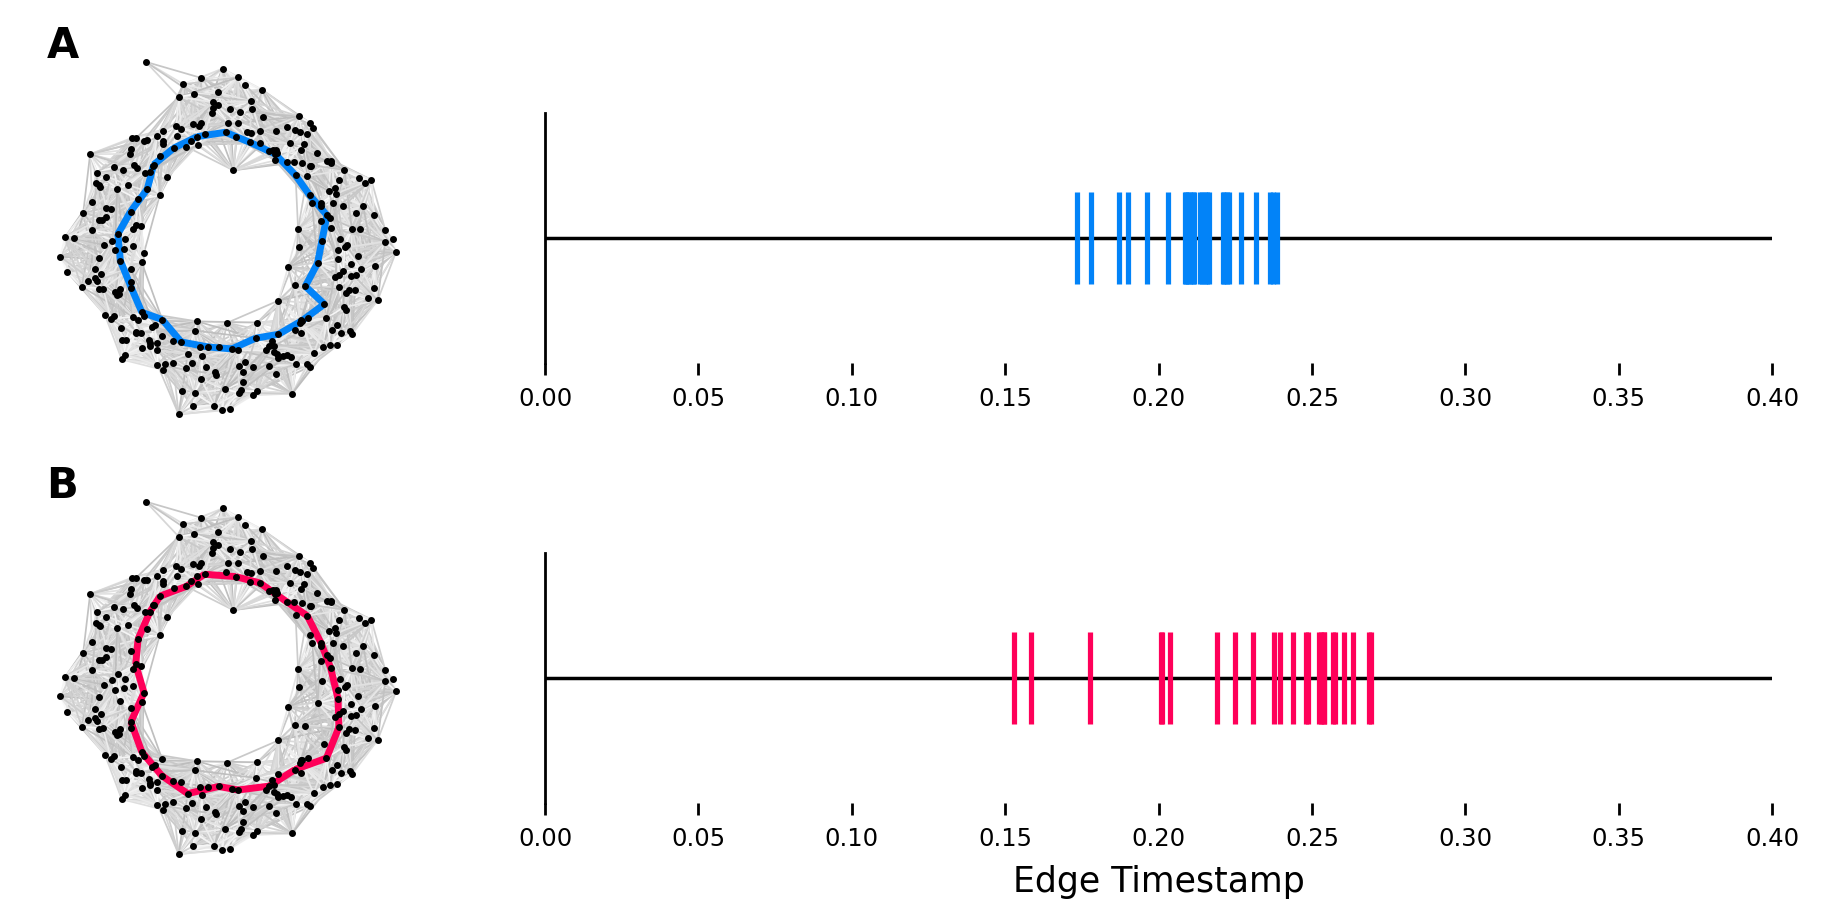

In [36]:
# Create 3D subplots
fig = plt.figure(figsize=(9.5, 4.5), dpi=250)

# Adjusting the grid specification
gs = fig.add_gridspec(
    6, 2, 
    height_ratios=[0.3, 1, 0.3, 0.3, 1, 0.3],  # Equal height for both rows
    width_ratios=[1, 2],  # Wider right column, smaller left column
    wspace=0,  # Slight space between columns (you can adjust this)
    hspace=0.1   # Space between rows (adjust to your preference)
)

# Embedding plot (3D plot on the left)
ax_A = fig.add_subplot(gs[:3, 0])
ax_A.spines[["top", "right"]].set_visible(False)
ax_A.tick_params(axis='both', which='major', labelsize=5)
visualize_network(x,y,adj_matrix,extra_edges=mean_cycle, color=colors["blue"],ax=ax_A,max_weight=0.5)
ax_A.text(0.05, 1, 'A', transform=ax_A.transAxes, fontsize=12, va='top', ha='left', fontweight="bold")
ax_A.axis("square")

ax_B = fig.add_subplot(gs[3:, 0])
#visualize_network(x,y,adj_matrix,extra_edges=representative, color=colors["red"],ax=ax_B,max_weight=0.5)
visualize_network(x,y,adj_matrix,extra_edges=len_cycle, color=colors["red"],ax=ax_B,max_weight=0.5)
ax_B.text(0.05, 1, 'B', transform=ax_B.transAxes, fontsize=12, va='top', ha='left', fontweight="bold")
ax_B.spines[["top", "right"]].set_visible(False)
ax_B.tick_params(axis='both', which='major', labelsize=5)
ax_B.axis("square")


# Example 1: First plot on the top right
ax = fig.add_subplot(gs[1, 1])
ax.spines[["top","right","bottom"]].set_visible(False)
ax.axhline(0,color="k",linewidth=1)
#ax.scatter(adj_matrix.flatten(),[0]*len(adj_matrix.flatten()), marker="|", color="lightgray",zorder=2)
ax.scatter([adj_matrix[a][b] for (a,b) in mean_cycle],[0]*len(mean_cycle),  s=700,color=colors["blue"], marker="|", label="Objective",zorder=2)
ax.set_xlim((0,0.4))
#ax.set_xlabel("Edge Timestamp")
ax.tick_params(axis='x', which='major', labelsize=7)
ax.set_yticks([])



# Example 2: Second plot on the bottom right
ax = fig.add_subplot(gs[4, 1])

ax.spines[["top","right","bottom"]].set_visible(False)
ax.axhline(0,color="k",linewidth=1)
#ax.scatter([adj_matrix[a][b] for (a,b) in representative], [0]*len(representative),s=700,  color=colors["red"], marker="|",label="Representive",zorder=2)
ax.scatter([adj_matrix[a][b] for (a,b) in len_cycle], [0]*len(len_cycle),s=700,  color=colors["red"], marker="|",label="Minimal",zorder=2)
ax.set_xlim((0,0.4))
ax.set_xlabel("Edge Timestamp")
ax.tick_params(axis='x', which='major', labelsize=7)
ax.set_yticks([])


plt.savefig("Figures/example_network_minimal_mean.png",bbox_inches='tight')
plt.show()

In [35]:
# print
cost_func = time_matrix(adj_matrix)
time_cost = 0
for a in mean_cycle:
    for b in mean_cycle:
        time_cost+=cost_func(a,b)
len_cost = 0
for a in len_cycle:
    for b in len_cycle:
        len_cost+=cost_func(a,b)
rep_cost = 0
for a in representative:
    for b in representative:
        rep_cost+=cost_func(a,b)
print(f"Method | Cycle Length | Time Dispersion")
print(f"Initial Representative |{len(representative)}|{rep_cost:.2f} ")
print(f"Time-Optimal |{len(mean_cycle)}|{time_cost:.2f} ")
print(f"L_0 Optimal |{len(len_cycle)}|{len_cost:.2f} ")


Method | Cycle Length | Time Dispersion
Time-Optiaml |26|12.24 
L_0 Minimization |24|20.15 
Initial Representative |75|255.69 


In [30]:
cost

np.float64(12.24447062286519)

In [19]:
len(mean_cycle)

26

# Visualization

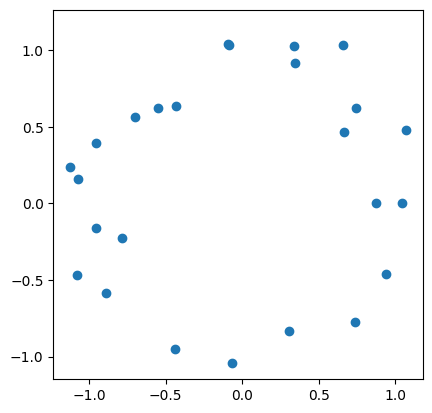

In [50]:
from sklearn.metrics import pairwise_distances

bounds = 3.2*np.pi
size = 25
noise = 0.2
theta = np.linspace(0, bounds, size)
x = np.cos(theta)*np.random.normal(loc=1, scale=noise, size=size)
y = np.sin(theta)*np.random.normal(loc=1, scale=noise, size=size)
vis_matrix = pairwise_distances(np.c_[x,y])
plt.scatter(x,y)
plt.axis("square")
plt.show()

In [167]:
from matplotlib.colors import Normalize, LinearSegmentedColormap
# Define colors for consistent plotting
colors = ['#0283F8', '#0078F3', '#3369E8', '#605BDA', "#7D49CB",
          "#9331B7", "#A918A8", "#C4009A", "#DA008B", "#EA007B",
          "#F7006A", "#FF0059"]
n_bins = len(colors)
shap_cmap = mcolors.LinearSegmentedColormap.from_list("custom_cmap", colors, N=n_bins)


# Create a custom monochrome blue colormap (from very light blue to dark blue)
# Define the specified blue color (#1F77B4) for highest values
dark_blue = '#1F77B4'
# Convert hex to RGB and create a lighter version for lowest values
dark_blue_rgb = mcolors.to_rgb(dark_blue)
light_blue_rgb = mcolors.to_rgb('#D3E2EF')
#light_blue_rgb = tuple(min(1.0, c * 2.5) for c in dark_blue_rgb)  # Lighten the color

# Create a custom monochrome blue colormap
colors = [light_blue_rgb, dark_blue_rgb]  # Light version to specified blue
blue_cmap = LinearSegmentedColormap.from_list('blue_mono', colors, N=256)


In [164]:
vis_complex = gudhi.AlphaComplex(points=np.c_[x,y]).create_simplex_tree(1)

In [165]:
edges = [a for a in vis_complex.get_filtration() if len(a[0])==2]


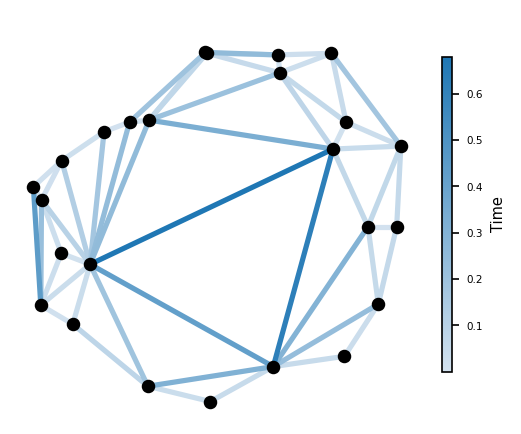

In [188]:
fig, ax = plt.subplots(figsize=(3.5, 3.5),dpi=150)

# Get edge values to determine color mapping
edge_values = [edge[1] for edge in edges]
norm = Normalize(vmin=min(edge_values), vmax=max(edge_values))

# Draw edges with colors based on their values
for ([start_idx, end_idx], value) in edges:
    ax.plot(
        [x[start_idx], x[end_idx]], 
        [y[start_idx], y[end_idx]], 
        '-', 
        color=blue_cmap(norm(value)), 
        linewidth=2.5,
        #alpha=0.3
    )

# Draw nodes
ax.scatter(x, y, s=30, c='black', edgecolors='black', zorder=10)
# Add node labels if needed
#for i, (xi, yi) in enumerate(np.c_[x,y]):
#    ax.text(xi, yi, f"{i}", fontsize=12, ha='center', va='center',zorder=11)

# Add a colorbar to show the value range
sm = plt.cm.ScalarMappable(cmap=blue_cmap, norm=norm)
sm.set_array([])
# Create the colorbar with custom positioning and size
cbar_ax = fig.add_axes([0.94, 0.2, 0.02, 0.6])  # [left, bottom, width, height]
cbar = plt.colorbar(sm, cax=cbar_ax, orientation='vertical')
cbar.set_label('Time',fontsize=7)
cbar.ax.tick_params(labelsize=5)

# Set limits slightly larger than the data
ax.set_xlim(min(x) - 0.5, max(x) + 0.5)
ax.set_ylim(min(y) - 0.5, max(y) + 0.5)
ax.axis("off")
ax.axis("square")
plt.savefig("Figures/partial_network.png",bbox_inches='tight')
plt.show()

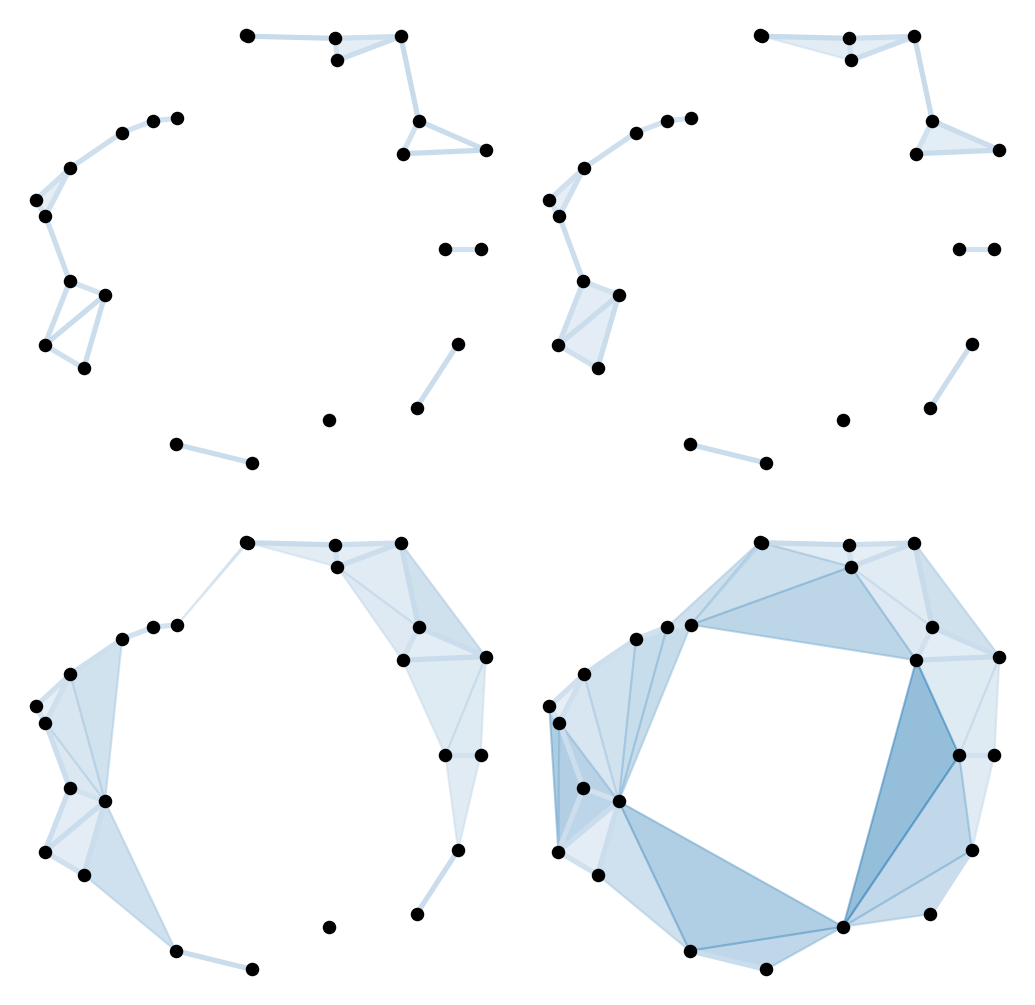

In [215]:
from itertools import combinations
edge_values = [edge[1] for edge in edges]
norm = Normalize(vmin=min(edge_values), vmax=max(edge_values))

# Calculate the number of edges for each subplot (e.g., 25%, 50%, 75%, 100% of N-1)
N = len(edges)
k_values = [math.ceil((i + 1) * N / 4) for i in range(3)] + [N - 1]
k_values = [min(k, N - 1) for k in k_values]  # Ensure k doesn’t exceed N-1

# Create a 2x2 grid of subplots
fig, axs = plt.subplots(2, 2, figsize=(7, 7), dpi=150)

# Set consistent axis limits across all subplots
min_x, max_x = min(x) - 0.1, max(x) + 0.1
min_y, max_y = min(y) - 0.1, max(y) + 0.1

# Determine the number of nodes
n = len(x)

# Create a dictionary mapping each edge to its index in the edges list
# Standardize edges as (min_idx, max_idx) to treat them as undirected
edge_index = {
    (min(edge[0][0], edge[0][1]), max(edge[0][0], edge[0][1])): idx
    for idx, edge in enumerate(edges)
}

# Plot each subplot
for i, ax in enumerate(axs.flat):
    k = k_values[i]
    # Set of edges in the current subgraph (first k edges)
    current_edges = set(
        (min(start_idx, end_idx), max(start_idx, end_idx))
        for ([start_idx, end_idx], _) in edges[:k]
    )
    
    # Find and plot filled triangles for all 3-cliques
    for i, j, k in combinations(range(n), 3):
        # Define the three edges of the potential triangle
        e1 = (min(i, j), max(i, j))
        e2 = (min(i, k), max(i, k))
        e3 = (min(j, k), max(j, k))
        # Check if all three edges exist in the current subgraph
        if e1 in current_edges and e2 in current_edges and e3 in current_edges:
            # Get the indices of the three edges in the original edges list
            idx1 = edge_index[e1]
            idx2 = edge_index[e2]
            idx3 = edge_index[e3]
            # The last edge has the highest index
            m = max(idx1, idx2, idx3)
            # Get the value of the last edge and its color
            value = edges[m][1]
            color = blue_cmap(norm(value))
            # Plot the filled triangle
            ax.fill(
                [x[i], x[j], x[k]],
                [y[i], y[j], y[k]],
                color=color,
                alpha=0.5,  # Semi-transparent to see edges underneath
                zorder=1   # Above edges (zorder=1) but below nodes (zorder=10)
            )
    
    # Plot edges
    for ([start_idx, end_idx], value) in edges[:k]:
        ax.plot(
            [x[start_idx], x[end_idx]],
            [y[start_idx], y[end_idx]],
            '-',
            color=blue_cmap(norm(value)),
            linewidth=2.5,
            zorder=5  # Default z-order for lines
        )
    
    # Plot nodes
    ax.scatter(
        x, y,
        s=30,
        c='black',
        edgecolors='black',
        zorder=10  # Nodes on top
    )
    
    # Apply consistent styling
    ax.set_xlim(min_x, max_x)
    ax.set_ylim(min_y, max_y)
    ax.set_aspect('equal')
    ax.axis('off')
plt.tight_layout()
plt.savefig("Figures/partial_network.png",bbox_inches='tight')
plt.show()

In [108]:
cycle2 = [[5,16],[16,1],[1,15],[15,14],[14,12],[12,23],[23,6],[6,21],[21,20],[20,5]]
cycle1 = [[5,4],[4,18],[18,2],[2,16],[16,15],[15,12],[12,10],[10,23],[23,5]]
time_cycle = [[5,4],[4,3],[3,17],[17,2],[2,1],[1,0],[0,14],[14,13],[13,12],[12,11],[11,10],[10,9],[9,23],[23,8],[8,22],[22,6],[6,21],[21,20],[20,5]]

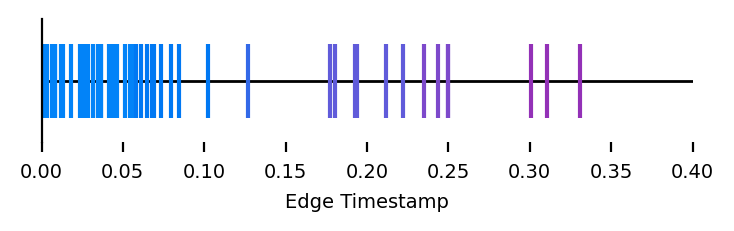

In [128]:
ffig, ax = plt.subplots(figsize=(4.2,0.8),dpi=200)
ax.spines[["top","right","bottom"]].set_visible(False)
ax.axhline(0,color="k",linewidth=1)

#ax.scatter([adj_matrix[a][b] for (a,b) in representative], [0]*len(representative),s=700,  color=colors["red"], marker="|",label="Representive",zorder=2)
ax.scatter([value for ([_,_],value) in edges], [0]*len(edges),s=700, c=[value for ([_,_],value) in edges], cmap =shap_cmap, marker="|",label="Minimal",zorder=2)
ax.set_xlim((0,0.4))
ax.set_xlabel("Edge Timestamp",fontsize=7)
ax.tick_params(axis='x', which='major', labelsize=7)
ax.set_yticks([])
plt.show()

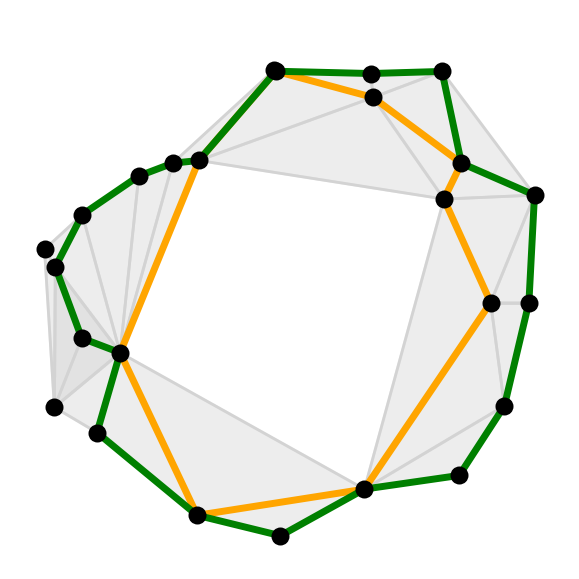

In [214]:
import itertools
fig, ax = plt.subplots(figsize=(3.5, 3.5), dpi=200)

# Get edge values to determine color mapping (kept for consistency, though not used here)
edge_values = [edge[1] for edge in edges]
norm = Normalize(vmin=min(edge_values), vmax=max(edge_values))

# Identify the last edge to exclude
last_edge = tuple(sorted(edges[-1][0]))  # Standardized as (min_idx, max_idx)

# Create a set of edges excluding the last one for triangle detection
subgraph_edges = set(tuple(sorted(edge[0])) for edge in edges[:-1])

# Find all 3-cliques in the subgraph
n = len(x)  # Number of nodes
triangles = []
for i, j, k in itertools.combinations(range(n), 3):
    e1 = (min(i, j), max(i, j))
    e2 = (min(i, k), max(i, k))
    e3 = (min(j, k), max(j, k))
    if e1 in subgraph_edges and e2 in subgraph_edges and e3 in subgraph_edges:
        triangles.append((i, j, k))

# Plot the filled triangles with a subtle color
for tri in triangles:
    ax.fill(
        [x[tri[0]], x[tri[1]], x[tri[2]]],
        [y[tri[0]], y[tri[1]], y[tri[2]]],
        color='lightgray',
        alpha=0.4,  # Subtle transparency
        zorder=0    # Ensure triangles are beneath edges
    )

# Draw light gray edges excluding the last one
for ([start_idx, end_idx], value) in edges[:-1]:
    ax.plot(
        [x[start_idx], x[end_idx]],
        [y[start_idx], y[end_idx]],
        '-',
        color="lightgray",
        linewidth=1,
        zorder=1
    )

# Draw orange edges for cycle1, excluding the last edge if present
for [start_idx, end_idx] in cycle1:
    if tuple(sorted([start_idx, end_idx])) != last_edge:
        ax.plot(
            [x[start_idx], x[end_idx]],
            [y[start_idx], y[end_idx]],
            '-',
            color="orange",
            linewidth=2.5,
            zorder=2
        )

# Draw green edges for time_cycle, excluding the last edge if present
for [start_idx, end_idx] in time_cycle:
    if tuple(sorted([start_idx, end_idx])) != last_edge:
        ax.plot(
            [x[start_idx], x[end_idx]],
            [y[start_idx], y[end_idx]],
            '-',
            color="green",
            linewidth=2.5,
            zorder=2
        )

# Draw nodes
ax.scatter(x, y, s=30, c='black', edgecolors='black', zorder=10)

# Set limits slightly larger than the data
ax.set_xlim(min(x) - 0.5, max(x) + 0.5)
ax.set_ylim(min(y) - 0.5, max(y) + 0.5)
ax.axis("off")

ax.axis("square")  # Replaces ax.axis("square") for consistency
plt.savefig("Figures/partial_network_cycles.png")
plt.show()

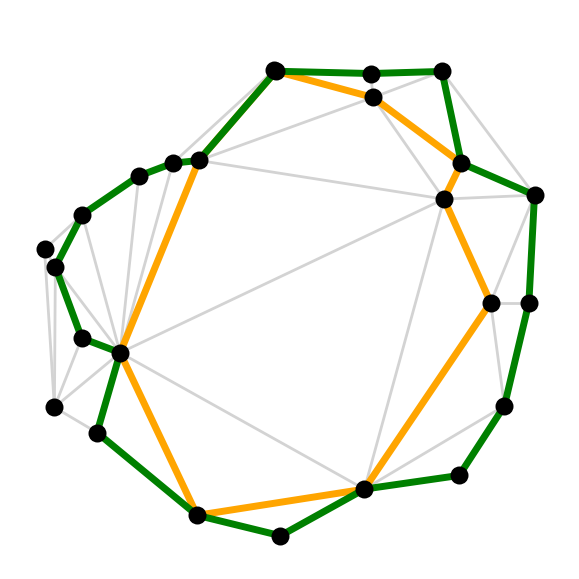

In [139]:
fig, ax = plt.subplots(figsize=(3.5, 3.5),dpi=200)

# Get edge values to determine color mapping
edge_values = [edge[1] for edge in edges]
norm = Normalize(vmin=min(edge_values), vmax=max(edge_values))

# Draw edges with colors based on their values
for ([start_idx, end_idx], value) in edges:
    ax.plot(
        [x[start_idx], x[end_idx]], 
        [y[start_idx], y[end_idx]], 
        '-', 
        color="lightgray", 
        linewidth=1
    )

# Draw edges with colors based on their values
for [start_idx, end_idx] in cycle1:
    ax.plot(
        [x[start_idx], x[end_idx]], 
        [y[start_idx], y[end_idx]], 
        '-', 
        color="orange", 
        linewidth=2.5
    )

# Draw edges with colors based on their values
for [start_idx, end_idx] in time_cycle:
    ax.plot(
        [x[start_idx], x[end_idx]], 
        [y[start_idx], y[end_idx]], 
        '-', 
        color="green", 
        linewidth=2.5
    )

# Draw nodes
ax.scatter(x, y, s=30, c='black', edgecolors='black', zorder=10)
# Add node labels if needed
#for i, (xi, yi) in enumerate(np.c_[x,y]):
#    ax.text(xi, yi, f"{i}", fontsize=12, ha='center', va='center',zorder=11)

# Add a colorbar to show the value range
sm = plt.cm.ScalarMappable(cmap=shap_cmap, norm=norm)
sm.set_array([])
#cbar = plt.colorbar(sm, ax=ax)
#cbar.set_label('Edge Values')

# Set limits slightly larger than the data
ax.set_xlim(min(x) - 0.5, max(x) + 0.5)
ax.set_ylim(min(y) - 0.5, max(y) + 0.5)
ax.axis("off")
ax.axis("square")
#plt.savefig("Figures/partial_network_cycles.png")
plt.show()

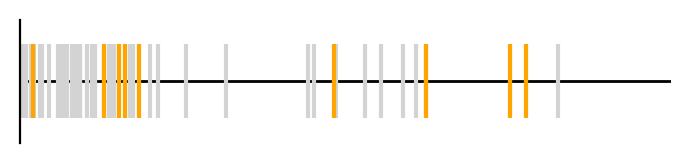

In [140]:
fig, ax = plt.subplots(figsize=(4.2,0.8),dpi=200)
ax.spines[["top","right","bottom"]].set_visible(False)
ax.axhline(0,color="k",linewidth=1)

filt = {tuple(np.sort(edge)):value for (edge, value) in edges}

#ax.scatter([adj_matrix[a][b] for (a,b) in representative], [0]*len(representative),s=700,  color=colors["red"], marker="|",label="Representive",zorder=2)
ax.scatter([value for ([_,_],value) in edges], [0]*len(edges),s=700, color="lightgray", marker="|",label="Minimal",zorder=2)
ax.scatter([filt[tuple(np.sort(edge))] for edge in cycle1], [0]*len(cycle1),s=700, color="orange", marker="|",label="Minimal",zorder=2)
ax.set_xlim((0,0.4))
#ax.set_xlabel("Edge Timestamp",fontsize=7)
ax.tick_params(axis='x', which='major', labelsize=7)
ax.set_yticks([])
ax.set_xticks([])
plt.savefig("Figures/partial_network_time_orange.png")
plt.show()

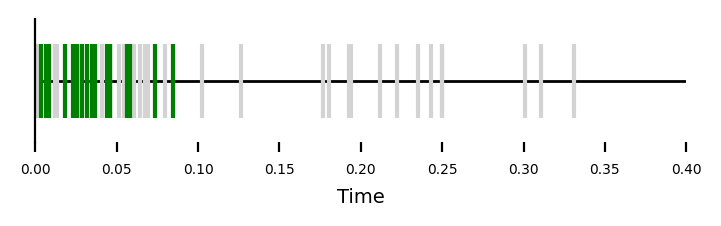

In [191]:
fig, ax = plt.subplots(figsize=(4.2,0.8),dpi=200)
ax.spines[["top","right","bottom"]].set_visible(False)
ax.axhline(0,color="k",linewidth=1)

filt = {tuple(np.sort(edge)):value for (edge, value) in edges}

#ax.scatter([adj_matrix[a][b] for (a,b) in representative], [0]*len(representative),s=700,  color=colors["red"], marker="|",label="Representive",zorder=2)
ax.scatter([value for ([_,_],value) in edges], [0]*len(edges),s=700, color="lightgray", marker="|",label="Minimal",zorder=2)
ax.scatter([filt[tuple(np.sort(edge))] for edge in time_cycle], [0]*len(time_cycle),s=700, color="green", marker="|",label="Minimal",zorder=2)
ax.set_xlim((0,0.4))
ax.set_xlabel("Time",fontsize=7)
ax.tick_params(axis='x', which='major', labelsize=5)
ax.set_yticks([])
plt.savefig("Figures/partial_network_time_green.png",bbox_inches='tight')
plt.show()

[([4, 19], 2.3463335928699427e-05),
 ([7, 22], 0.0021399079758357194),
 ([3, 18], 0.0028917151307241828),
 ([5, 20], 0.0034509182812438),
 ([20, 21], 0.006617013606052465),
 ([0, 15], 0.007332755262131972),
 ([2, 16], 0.007991908759412678),
 ([8, 23], 0.00847270059878382),
 ([9, 24], 0.012285493097466273),
 ([6, 7], 0.013212904432122707),
 ([6, 22], 0.018014620035039345),
 ([6, 21], 0.02342867457998688),
 ([3, 17], 0.025412137594679626),
 ([17, 18], 0.027272664220088325),
 ([8, 24], 0.02774040231997954),
 ([8, 22], 0.02887296358260605),
 ([1, 2], 0.03189004624399901),
 ([13, 14], 0.03453793621861478),
 ([9, 23], 0.034601045042099876),
 ([23, 24], 0.036589180702155395),
 ([10, 11], 0.036853657813112055),
 ([1, 16], 0.041275661444779344),
 ([2, 17], 0.044100071659262496),
 ([3, 4], 0.04518035324384438),
 ([12, 13], 0.04603076060342616),
 ([11, 12], 0.04616980873861721),
 ([4, 18], 0.051333058979203636),
 ([14, 15], 0.054380341279685204),
 ([0, 14], 0.05643204456735941),
 ([0, 1], 0.05800